# Homework 1 Group 15
Empirical Methods in Finance

## Question 1

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import norm
from statsmodels.stats.stattools import jarque_bera
import statsmodels.api as sm
from statsmodels.iolib.summary2 import summary_col
import statsmodels.formula.api as smf

### a) Importing the data into Python

In [ ]:
# Load the monthly returns from the 'stock_monthly' sheet,
# using DATE as the index
df = pd.read_excel("data_assignment1.xlsx", sheet_name="stock_monthly",
                   index_col="DATE")

# first check of the data
display(df.dtypes) 
display(df.head())

MICROSOFT    float64
COCACOLA     float64
EXXON        float64
VWRET        float64
EWRET        float64
dtype: object

,MICROSOFT,COCACOLA,EXXON,VWRET,EWRET
DATE,,,,,
1990-01-31,0.063218,-0.108414,-0.060000,-0.070114,-0.046408
1990-02-28,0.067568,0.023593,0.012766,0.014900,0.015434
1990-03-30,0.121519,0.065957,-0.018617,0.024148,0.021315
1990-04-30,0.047404,0.020067,-0.018970,-0.028283,-0.028116
1990-05-31,0.258621,0.183607,0.074033,0.088935,0.045673


### b) Transforming simple returns into log returns

In [13]:
# Convert simple returns to log returns: r_t = ln(1 + R_t)
df_log = np.log(df + 1)
df_log.head()

,MICROSOFT,COCACOLA,EXXON,VWRET,EWRET
DATE,,,,,
1990-01-31,0.061301,-0.114754,-0.061875,-0.072693,-0.047519
1990-02-28,0.065383,0.023319,0.012685,0.014790,0.015316
1990-03-30,0.114684,0.063873,-0.018792,0.023861,0.021091
1990-04-30,0.046315,0.019868,-0.019152,-0.028691,-0.028519
1990-05-31,0.230016,0.168566,0.071421,0.085200,0.044661


### c) Plotting simple and log returns over time for each return series

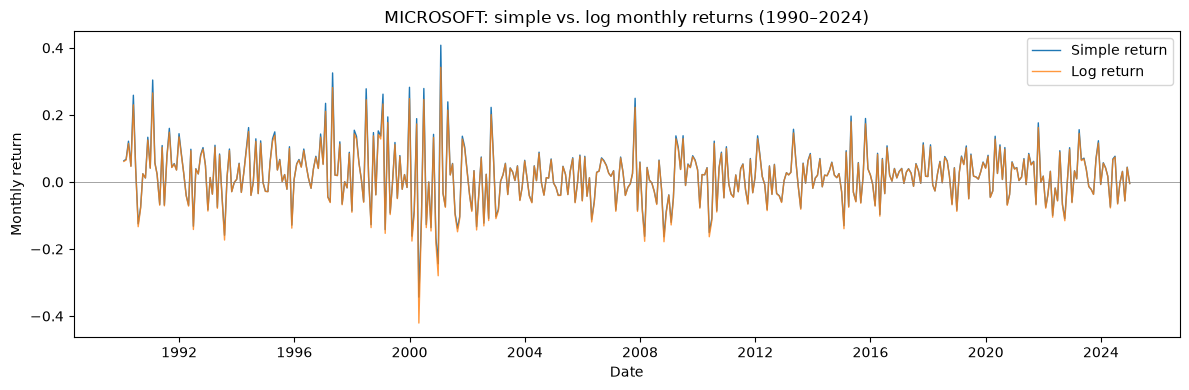

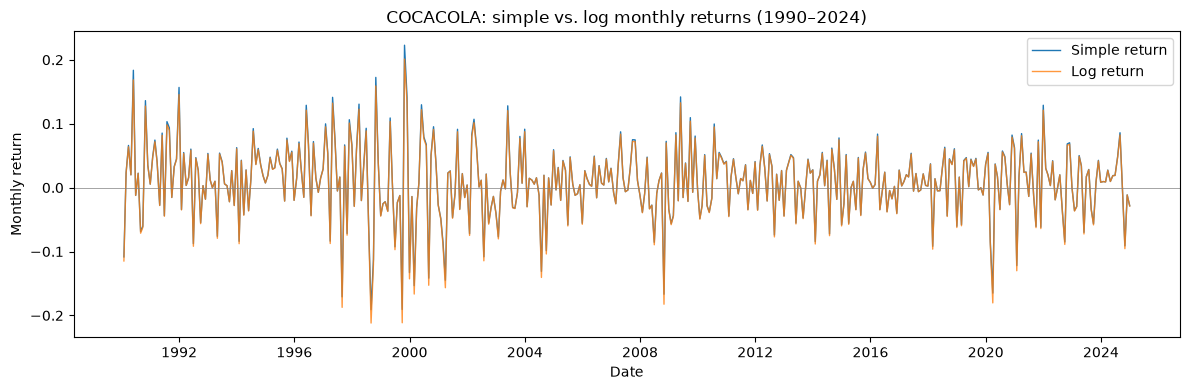

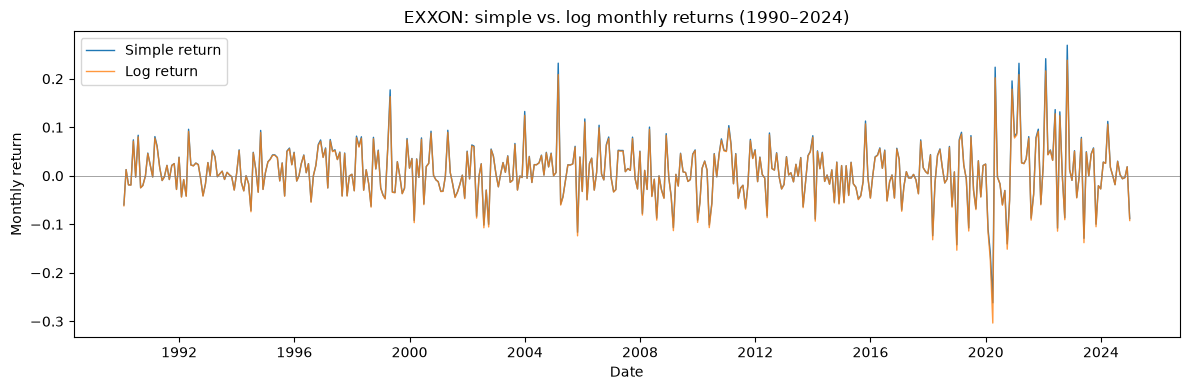

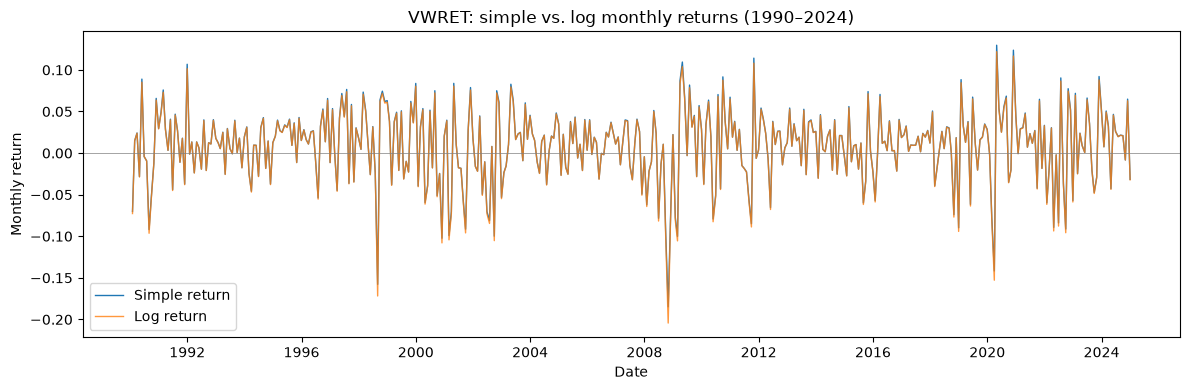

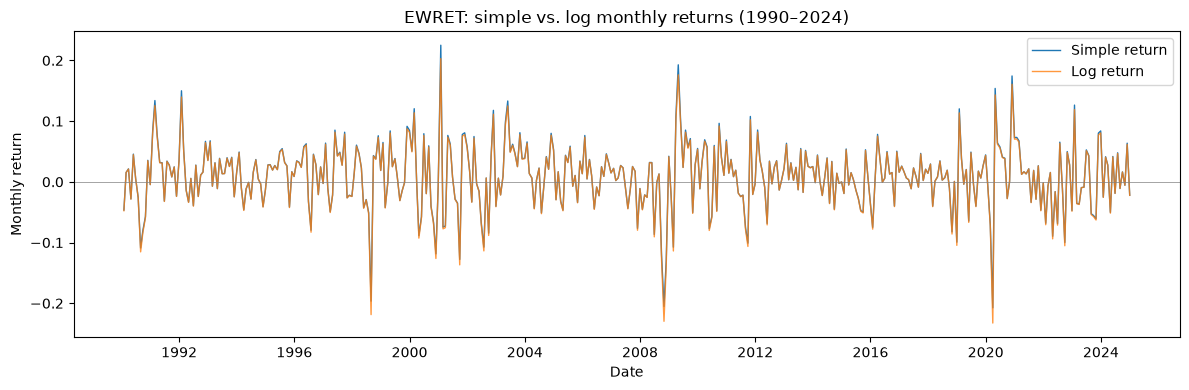

In [ ]:
# Plot simple vs. log returns over time, one figure per series
for col in df.columns:
    fig, ax = plt.subplots(figsize=(12, 4))

    ax.plot(df.index, df[col], label="Simple return", linewidth=1) # plotting simple return
    ax.plot(df_log.index, df_log[col], label="Log return", linewidth=1, alpha=0.8) # plotting log return

    ax.axhline(0, color="grey", linewidth=0.5)   # zero line for reference
    ax.set_title(f"{col}: simple vs. log monthly returns (1990–2024)")
    ax.set_xlabel("Date")
    ax.set_ylabel("Monthly return")
    ax.legend()
    plt.tight_layout()
    plt.show()

For all five series, simple and log returns are almost identical in most months. This is expected: for small returns, $\ln(1+R) \approx R$. The two series clearly separate only in months with extreme returns.

In those months the log return is always below the simple return, for gains and losses alike. The log function is concave and lies below the line $y = R$ everywhere except at $R = 0$, so log returns are always smaller than simple returns, and more so for large moves, especially large losses.

The gap between simple and log returns is clearly larger for the individual stocks (Microsoft, Coca-Cola, ExxonMobil) than for the VW and EW indices. Single stocks are more volatile and have more extreme months, while the indices are diversified, so firm-specific shocks largely cancel out.

All series show volatility clustering: large returns occur in bunches during turbulent periods rather than being spread evenly over time. The main periods are:

- the dot-com bubble and crash (around 1998–2002), especially visible for Microsoft
- the global financial crisis (2008–2009)
- the COVID-19 shock (2020), clearly visible for Coca-Cola, ExxonMobil and both indices

Microsoft shows relatively little extra volatility around COVID-19. This is plausible because the pandemic increased demand for its software and cloud services (remote work, online meetings), which helped offset the market-wide shock.

### d) Computing the correlation matrix of the log-return series

,MICROSOFT,COCACOLA,EXXON,VWRET,EWRET
MICROSOFT,1.000000,0.225701,0.180323,0.575206,0.462633
COCACOLA,0.225701,1.000000,0.321861,0.435905,0.280963
EXXON,0.180323,0.321861,1.000000,0.488712,0.410605
VWRET,0.575206,0.435905,0.488712,1.000000,0.875098
EWRET,0.462633,0.280963,0.410605,0.875098,1.000000


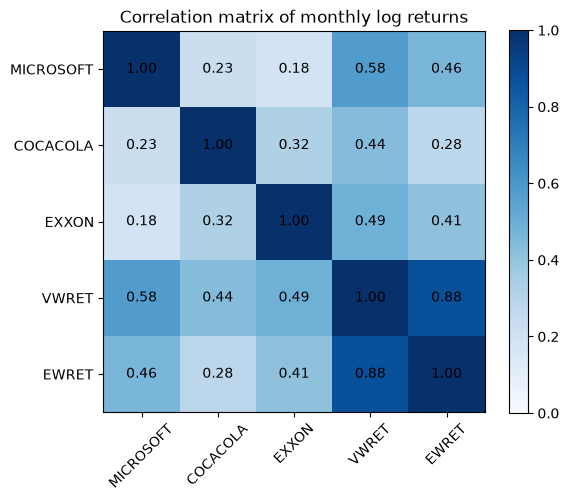

In [24]:
# Correlation matrix of the five log-return series
corr = df_log.corr()
corr.round(2) # to make the table easier to read
display(corr)

# Heatmap of the correlation matrix
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45)
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im)
ax.set_title("Correlation matrix of monthly log returns")
plt.tight_layout()
plt.show()

All three stocks are positively correlated with both market indices, ranging from 0.28 (Coca-Cola–EW) to a fairly high 0.58 (Microsoft–VW). Even in the strongest case, the market accounts for only about one third of the stock’s variance ($0.58^2 \approx 0.33$), so a large part of each stock’s return is firm-specific.

Each stock is more strongly correlated with the value-weighted index than with the equal-weighted one. In the VW index, large firms like these three make up a substantial share of the index itself. The EW index gives every firm the same weight, so it is driven mostly by many small firms, which react to different shocks than large caps do.

Coca-Cola has the lowest correlation with both indices. This fits its profile as a defensive consumer-staples stock: demand for its products is fairly stable over the business cycle. Whether it really has lower market exposure is tested with its beta in (i).

The three stocks are only weakly correlated with each other (0.18–0.32), which reflects their different sectors (technology, consumer staples, energy). This suggests large diversification benefits from combining them.

The two indices are highly but not perfectly correlated (0.88). Both track the overall market, but they weight large and small firms differently.

### e) Scatterplot of log returns of individual stocks against value-weighted index

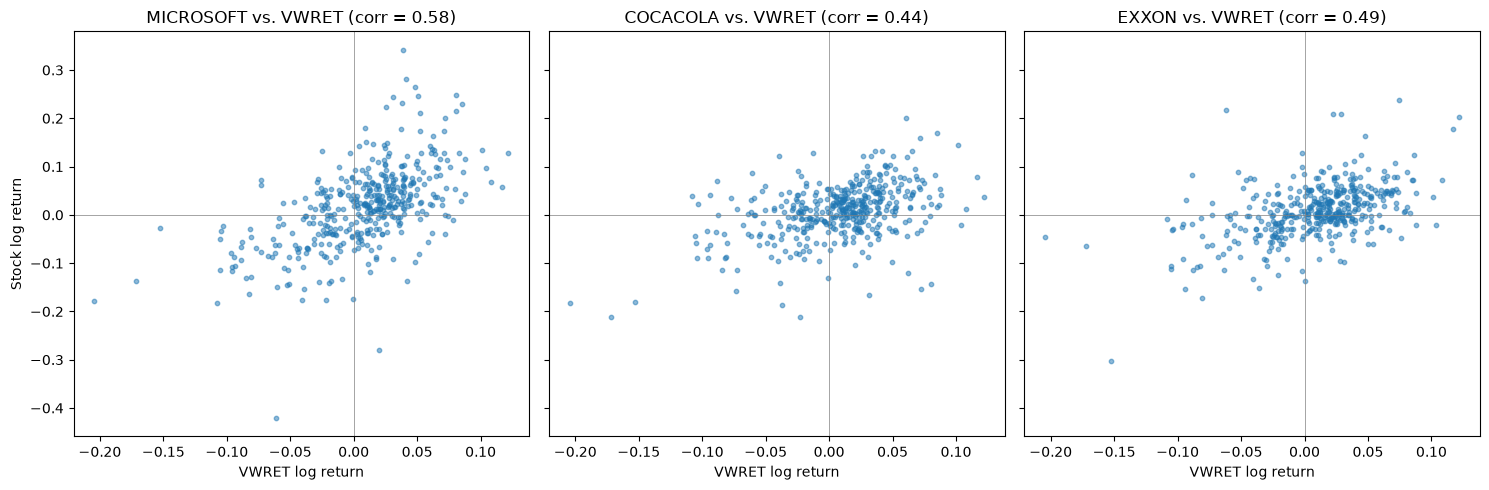

In [27]:
# Scatterplots of each stock's log returns against the VW index
stocks = ["MICROSOFT", "COCACOLA", "EXXON"]

# to create a visual with one row and three panels
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True, sharey=True) 

for ax, stock in zip(axes, stocks): # pairing each panel with one stock
    x = df_log["VWRET"]
    y = df_log[stock]

    ax.scatter(x, y, s=10, alpha=0.5)

    ax.axhline(0, color="grey", linewidth=0.5)
    ax.axvline(0, color="grey", linewidth=0.5)
    ax.set_title(f"{stock} vs. VWRET (corr = {x.corr(y):.2f})")
    ax.set_xlabel("VWRET log return")

axes[0].set_ylabel("Stock log return")
plt.tight_layout()
plt.show()

In [ ]:
# Checking the outliers for Microsoft as illustration

# Months with the largest gap between Microsoft's and the market's return
gap = (df_log["MICROSOFT"] - df_log["VWRET"])
display(df_log.loc[gap.abs().nlargest(5).index, ["MICROSOFT", "VWRET"]])

,MICROSOFT,VWRET
DATE,,
2000-04-28,-0.420877,-0.061363
2001-01-31,0.342015,0.038810
2000-12-29,-0.279725,0.020243
1997-04-30,0.281528,0.041522
1991-01-31,0.265426,0.047917


All three scatterplots show a positive relationship between the stock’s log returns and the VW index. The value-weighted index (VWRET) can be seen as a proxy for the overall market: it weights each firm by its market capitalization, so it reflects the return on the aggregate value of all stocks. When the value-weighted index (market proxy) rises, the stocks tend to rise too. Most observations are concentrated around the origin, since monthly returns are usually small. The spread is wide, though, especially for Coca-Cola, whose cloud is the roundest. This matches the moderate correlations found in (d): a large part of each stock’s return is firm-specific.

Microsoft’s cloud is visibly steeper than those of Coca-Cola and ExxonMobil, so Microsoft tends to react more strongly to market movements. Its points are also spread much more widely along the vertical axis, which suggests its returns are more volatile; we confirm this with the variances in (f). Coca-Cola and ExxonMobil react less strongly, which fits their profile as more defensive stocks. We quantify this sensitivity with the CAPM betas in (i).

The plots show several outliers: months in which a stock moved far more than the market. For Microsoft, the largest ones fall around the dot-com bubble and crash:

April 2000: −42% vs. −6% for the market, coinciding with the ruling against Microsoft in its antitrust case
December 2000: −28% vs. +2%
January 2001: +34% vs. +4%

These are firm- and sector-specific shocks that the broad market barely reflected. 

### f) Computing sample mean, variance, skewness, excess kurtosis, minimum and maximum of all log return series

In [29]:
# Summary statistics of the five log-return series
stats = pd.DataFrame({
    "Mean":            df_log.mean(),
    "Variance":        df_log.var(),
    "Standard deviation": df_log.std(),
    "Skewness":        df_log.skew(),
    "Excess kurtosis": df_log.kurt(),
    "Min":             df_log.min(),
    "Max":             df_log.max(),
})

display(stats.round(4))

,Mean,Variance,Standard deviation,Skewness,Excess kurtosis,Min,Max
MICROSOFT,0.0167,0.0071,0.0840,-0.1150,2.5226,-0.4209,0.3420
COCACOLA,0.0080,0.0033,0.0570,-0.5686,1.9066,-0.2119,0.2011
EXXON,0.0079,0.0032,0.0569,-0.0934,3.7131,-0.3036,0.2384
VWRET,0.0080,0.0020,0.0444,-0.8329,1.8635,-0.2044,0.1219
EWRET,0.0082,0.0028,0.0530,-0.5789,2.8318,-0.2326,0.2030


Across all series, the individual stocks are more volatile than the indices, which reflects the diversification of firm-specific risk in the indices. Microsoft has by far the highest mean return (1.67% per month) and the highest standard deviation (8.4%). All five series are negatively skewed and have positive excess kurtosis, so large losses are more likely than large gains and extreme returns occur more often than under a normal distribution.

Comparing the two indices, both earn almost the same average monthly return: 0.80% for VW and 0.82% for EW. The EW index, however, carries more risk:

higher standard deviation: 5.3% vs. 4.4%
fatter tails: excess kurtosis of 2.83 vs. 1.86
a worse worst month: −23.3% vs. −20.4%

The only measure that points the other way is skewness: the VW index is more negatively skewed (−0.83 vs. −0.58), so its losses are somewhat more asymmetric. The higher volatility and kurtosis of the EW index still dominate. This is because the EW index gives small firms the same weight as large ones. Small caps are more volatile, less liquid and more sensitive to crises, whereas the VW index is dominated by large, more stable firms.

From an investment perspective, the EW index therefore carries more risk without compensating its investors with a meaningfully higher return. Assuming a zero risk-free rate, a simple Sharpe ratio (mean divided by standard deviation) is about 0.18 for VW and 0.15 for EW. The VW index offers the better risk-return trade-off.

### g) t-Test

For each of the five series we test:

$H_0: \mu = 0$ (the true average monthly log return is zero)
$H_1: \mu \neq 0$ (two-sided: it could be positive or negative)
The test statistic
$$t = \frac{\bar{r} - 0}{s / \sqrt{n}}$$
$\bar{r}$ is the sample mean
$s$ is the sample standard deviation
$n = 420$ months
$s/\sqrt{n}$ is the standard error of the mean: how precisely the mean is estimated

Under $H_0$, $t$ follows a t-distribution with $n - 1 = 419$ degrees of freedom. With that many observations, it’s practically a normal distribution, so the 5% two-sided critical value is about ±1.97. We reject $H_0$ if $|t| > 1.97$, or equivalently if the p-value is below 0.05.

In [ ]:
# Two-sided one-sample t-test of H0: mean log return = 0, for each series
results = []
for col in df_log.columns:
    t_stat, p_val = stats.ttest_1samp(df_log[col], popmean=0)
    results.append({"Series": col,
                    "Mean": df_log[col].mean(),
                    "t-stat": t_stat,
                    "p-value": p_val,
                    "Reject H0 at 5%": p_val < 0.05})

ttest = pd.DataFrame(results).set_index("Series")
display(ttest.round(4))

# Manual check for VWRET (just to confirm)
r = df_log["VWRET"]
t_manual = r.mean() / (r.std() / np.sqrt(len(r)))
print(f"Manual t-stat for VWRET: {t_manual:.4f}")

,Mean,t-stat,p-value,Reject H0 at 5%
Series,,,,
MICROSOFT,0.0167,4.0874,0.0001,True
COCACOLA,0.0080,2.8927,0.0040,True
EXXON,0.0079,2.8554,0.0045,True
VWRET,0.0080,3.7031,0.0002,True
EWRET,0.0082,3.1815,0.0016,True


Manual t-stat for VWRET: 3.7031


We reject $H_0$ at the 5% level for all five series: every p-value is below 0.05 and every |t| is above about 1.97. Since all estimated means are positive, average monthly log returns are significantly positive.

Although the means look small, the long sample makes the standard error ($s/\sqrt{n}$) small, so they are estimated precisely. They are also economically meaningful: a mean of about 0.8% per month corresponds to roughly 9.6% per year in log terms. Over the long run, investors in these stocks and indices earned a positive average return.

The t-statistic can be written as $(\bar{r}/s) \times \sqrt{n}$, so it is proportional to a simple Sharpe ratio. This explains the ranking:

- The VW and EW indices have almost the same mean, but EW is more volatile, so its t-statistic is lower (3.18 vs. 3.70). This is consistent with its weaker risk-return trade-off in (f).
- Microsoft has the highest t-statistic despite being the most volatile, because its mean is about twice as large.
- Coca-Cola and ExxonMobil have the lowest t-statistics: their means are similar to the indices’, but their volatility is higher.

The t-test formally assumes independent, normally distributed returns. As shown in (f), the returns are skewed and fat-tailed. With 420 observations, however, the central limit theorem ensures that the sample mean is approximately normal, so the test remains reasonable.

### h) Histograms and fitted normal density functions

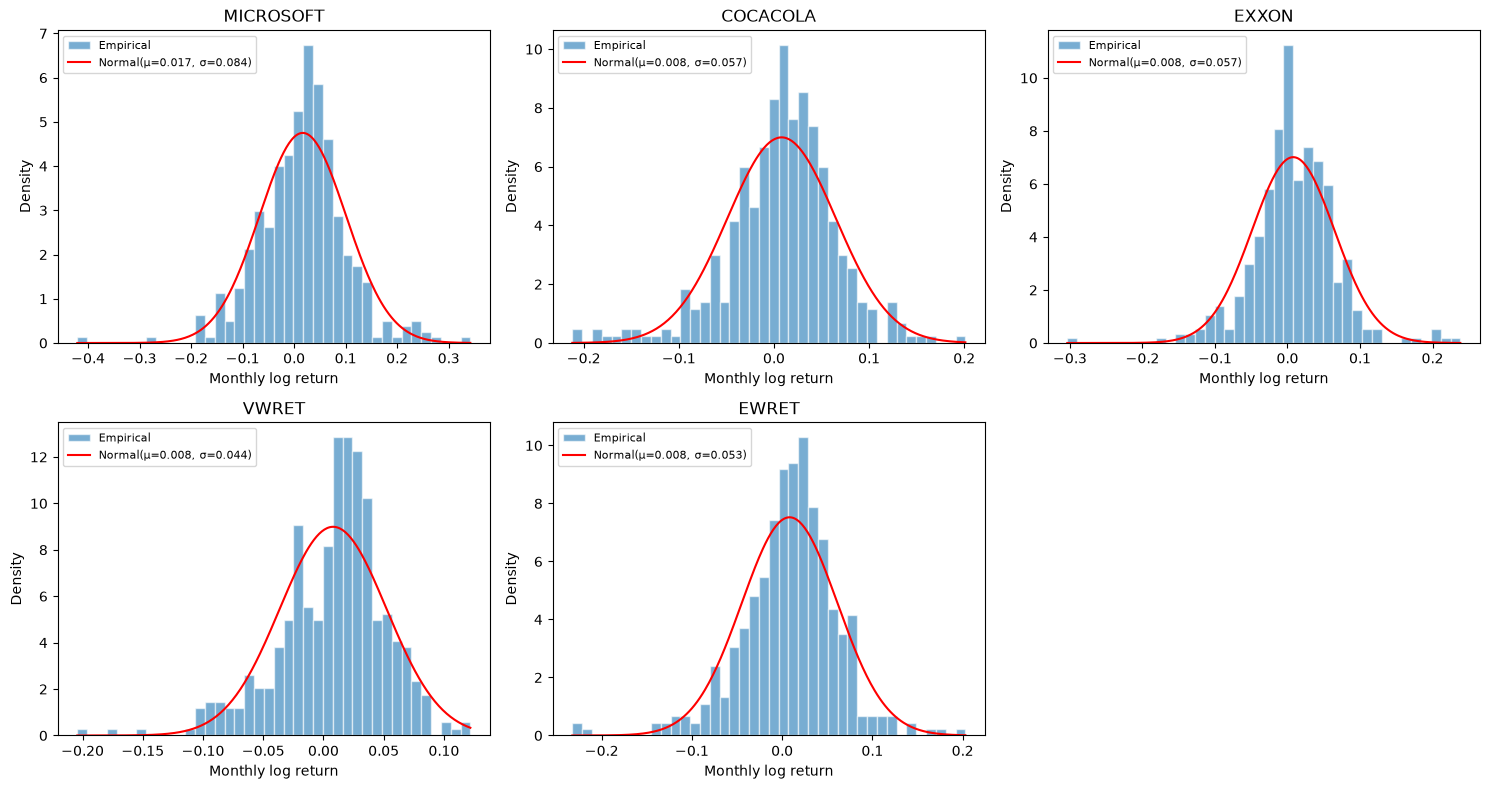

In [40]:
# Histograms of log returns with a fitted Normal density
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, col in zip(axes, df_log.columns):
    r = df_log[col]
    mu, sigma = r.mean(), r.std()

    # Histogram, scaled to a density so it is comparable to the Normal curve
    ax.hist(r, bins=40, density=True, alpha=0.6, edgecolor="white",
            label="Empirical")

    # Normal density with the same mean and standard deviation as the data
    x = np.linspace(r.min(), r.max(), 300)
    ax.plot(x, norm.pdf(x, mu, sigma), color="red", linewidth=1.5,
            label=f"Normal(μ={mu:.3f}, σ={sigma:.3f})")

    ax.set_title(col)
    ax.set_xlabel("Monthly log return")
    ax.set_ylabel("Density")
    ax.legend(fontsize=8)

axes[-1].axis("off")   # hide the unused sixth panel
plt.tight_layout()
plt.show()

The log returns do not appear to follow a normal distribution. The overall bell shape is similar, but all five histograms deviate from the fitted normal density in the same systematic way:

a taller and narrower peak around the mean
fatter tails, with extreme returns occurring more often than a normal distribution would predict
a longer left tail than right tail

The first two features mean the distributions are leptokurtic, which matches the positive excess kurtosis of every series in (f), ranging from 1.86 to 3.71. The longer left tail reflects negative skewness: large losses are more common than gains of the same size. This matches the negative skewness values in (f).

There is no clear answer to whether the indices or the individual stocks are closer to normal; it depends on the measure:
- Tails: the VW index has the lowest excess kurtosis, so the thinnest tails. ExxonMobil has the fattest, driven by oil-price shocks.
- Symmetry: the indices are more negatively skewed than Microsoft and ExxonMobil, with VWRET the most skewed of all. Diversification removes firm-specific shocks, which occur randomly in both directions. What remains is mainly market-wide shocks, and crashes such as 2008 and 2020 tend to be sharper than rallies.
- The EW index is not closer to normal than the stocks on either measure. It combines fairly strong negative skewness with relatively high kurtosis, reflecting the greater weight of small firms.

Overall, neither group is clearly closer to normal: the indices tend to have thinner tails but are more asymmetric. We test normality formally with the Jarque–Bera test below.

#### Jarque–Bera test

The Jarque–Bera test checks whether the skewness and kurtosis of the data are consistent with a normal distribution, which has skewness 0 and excess kurtosis 0.

The test
$H_0$: the returns are normally distributed
$H_1$: they are not

The test statistic is:

$$JB = \frac{n}{6}\left(S^2 + \frac{K^2}{4}\right)$$

where $S$ is the skewness and $K$ is the excess kurtosis. Both are squared, so any deviation from normality, in either direction, makes $JB$ larger. Under $H_0$, $JB$ follows a $\chi^2$ distribution with 2 degrees of freedom, so the 5% critical value is 5.99. We reject normality if $JB > 5.99$ or if the p-value is below 0.05.

JB is proportional to $n$, so with 420 observations, even moderate skewness or kurtosis produces a large statistic.

In [ ]:
# Jarque-Bera test of normality for each log-return series
jb_results = []
for col in df_log.columns:
    jb_stat, jb_pval, skew, kurt = jarque_bera(df_log[col])
    jb_results.append({"Series": col,
                       "JB stat": jb_stat,
                       "p-value": jb_pval,
                       "Skewness": skew,
                       "Excess kurtosis": kurt - 3,
                       "Reject normality at 5%": jb_pval < 0.05})

jb_table = pd.DataFrame(jb_results).set_index("Series")
display(jb_table.style.format({
    "JB stat": "{:.2f}",
    "p-value": "{:.2e}",          # scientific notation, e.g. 3.45e-24 to show small p-values
    "Skewness": "{:.4f}",
    "Excess kurtosis": "{:.4f}",
}))

,JB stat,p-value,Skewness,Excess kurtosis,Reject normality at 5%
Series,,,,,
MICROSOFT,108.42,2.87e-24,-0.1146,2.4784,True
COCACOLA,83.65,6.85e-19,-0.5666,1.8697,True
EXXON,234.37,1.28e-51,-0.0931,3.6548,True
VWRET,106.63,7.00e-24,-0.8299,1.8272,True
EWRET,158.93,3.08e-35,-0.5769,2.7840,True


We reject normality at the 5% level for all five series, by a wide margin. This confirms what the histograms and the summary statistics in (f) suggested.

Breaking down the statistic shows that the rejection is driven mainly by excess kurtosis (fat tails):

For ExxonMobil and Microsoft, almost the entire statistic comes from kurtosis.
VWRET is the only series where skewness contributes about as much as kurtosis.

This is consistent with the earlier finding that the indices are more negatively skewed than the individual stocks, while the stocks, especially ExxonMobil, have fatter tails. The test does not single out either group as normal: neither the indices nor the stocks are close to normally distributed.

Because the statistic is proportional to $n$, the JB test rejects even small deviations from normality in large samples. Here, however, the deviations are also substantial in absolute terms, with excess kurtosis between about 2 and 4.

A distribution with fatter tails would fit these returns better. The natural candidate is the Student-t distribution, whose degrees of freedom control how heavy the tails are. Since the t-distribution is symmetric, a skewed-t distribution would also capture the negative skewness, which is especially relevant for the indices.

### i) Estimating CAPM regression

For each stock, we estimate the CAPM regression with the risk-free rate set to zero:

$$r_{i,t} = \alpha_i + \beta_i \, r_{m,t} + \varepsilon_{i,t}$$

where $r_{i,t}$ is the stock’s log return and $r_{m,t}$ is the VWRET log return.

In [49]:
# CAPM regressions
# Model: r_i,t = alpha_i + beta_i * r_m,t + e_i,t
# Stock log returns on VWRET log returns (market proxy); risk-free rate = 0.
stocks = ["MICROSOFT", "COCACOLA", "EXXON"]

# Regressor matrix: VWRET plus a column of ones.
# Without add_constant, statsmodels estimates no intercept, so no alpha.
X = sm.add_constant(df_log["VWRET"])

# Estimate one OLS regression per stock and store the fitted models
capm_models = {}
for stock in stocks:
    capm_models[stock] = sm.OLS(df_log[stock], X).fit()   # y first, then X

# Side-by-side regression output
# Coefficients with standard errors in parentheses;
# stars mark significance: * 10%, ** 5%, *** 1%
print(summary_col(list(capm_models.values()),
                  model_names=stocks,
                  stars=True,
                  info_dict={"N":  lambda m: f"{int(m.nobs)}",}))

# Key estimates and tests in one table
capm_results = []
for stock, m in capm_models.items():
    capm_results.append({
        "Stock":      stock,
        "Alpha":      m.params["const"],
        "t (alpha)":  m.tvalues["const"],    # H0: alpha = 0
        "p (alpha)":  m.pvalues["const"],
        "Beta":       m.params["VWRET"],
        "t (beta=0)": m.tvalues["VWRET"],    # H0: beta = 0 (no market exposure)
        # H0: beta = 1 (stock as risky as the market); |t| > 1.97 rejects at 5%
        "t (beta=1)": (m.params["VWRET"] - 1) / m.bse["VWRET"],
        "R²":         m.rsquared,            # share of variance explained by the market
    })

capm_table = pd.DataFrame(capm_results).set_index("Stock")
display(capm_table.round(4))


               MICROSOFT  COCACOLA   EXXON  
--------------------------------------------
const          0.0080**  0.0036    0.0029   
               (0.0034)  (0.0025)  (0.0025) 
VWRET          1.0886*** 0.5601*** 0.6267***
               (0.0757)  (0.0566)  (0.0547) 
R-squared      0.3309    0.1900    0.2388   
R-squared Adj. 0.3293    0.1881    0.2370   
N              420       420       420      
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01


,Alpha,t (alpha),p (alpha),Beta,t (beta=0),t (beta=1),R²
Stock,,,,,,,
MICROSOFT,0.0080,2.3518,0.0191,1.0886,14.3765,1.1700,0.3309
COCACOLA,0.0036,1.3963,0.1634,0.5601,9.9024,-7.7776,0.1900
EXXON,0.0029,1.1780,0.2395,0.6267,11.4526,-6.8211,0.2388


**Alphas.** Under the CAPM, alpha should be zero: a stock’s expected return is fully explained by its market exposure.

For Coca-Cola and ExxonMobil we cannot reject $H_0: \alpha = 0$ at the 5% level. Their alphas (about 4.3% and 3.5% per year) are economically non-trivial but imprecisely estimated.
Microsoft’s alpha of 0.80% per month (about 9.6% per year) is significant at the 5% level and economically significant as well. The market factor alone does not fully explain Microsoft’s returns over this period.

Two caveats apply:

- Setting the risk-free rate to zero biases alpha. With excess returns, the true alpha is $\hat\alpha - r_f(1-\hat\beta)$. This barely affects Microsoft ($\beta \approx 1$) but means Coca-Cola’s and ExxonMobil’s alphas are somewhat overstated.
- Microsoft was chosen with hindsight as one of the most successful firms of the period. Its positive alpha reflects ex-post performance, not a return investors could have expected in 1990.

**Betas.** All three betas are positive and highly significant against $H_0: \beta = 0$. That test is not very informative, since almost any stock is exposed to the market. The more relevant benchmark is $\beta = 1$, the beta of the market itself:

Microsoft’s beta (1.09) is not significantly different from 1 ($t = 1.17$). It moves roughly one-for-one with the market.
Coca-Cola (0.56) and ExxonMobil (0.63) have betas significantly below 1 ($|t| > 1.97$). They are defensive stocks that react only about half as strongly to market movements. This confirms the hypothesis from (d) that Coca-Cola, as a consumer-staples firm, is less exposed to market fluctuations.

**R².** The market explains 33% of Microsoft’s return variance, but only 19% for Coca-Cola and 24% for ExxonMobil. These values equal the squared correlations from (d). A larger share of Coca-Cola’s and ExxonMobil’s risk is therefore firm-specific. In absolute terms, however, Microsoft has the highest idiosyncratic variance (about 0.0048, vs. 0.0027 and 0.0024), because its total variance is much larger. For all three stocks, most of the risk is idiosyncratic and could be diversified away. Under the CAPM, investors are only compensated for the systematic part, measured by beta.

## Question 2

### a) Importing data in python

In [55]:
# Load the pension data (Stata format)
pension = pd.read_stata("pension.dta")

# Quick checks: size, data types, first rows
print(f"Shape: {pension.shape}")
display(pension.head())
display(pension.describe())
display(pension.dtypes)

# Convert compact Stata types (int8, float32) to float64 to avoid overflow/precision issues
pension = pension.astype("float64")

# Variable descriptions stored in the Stata file
reader = pd.io.stata.StataReader("pension.dta")
display(reader.variable_labels())

Shape: (9275, 11)


,e401k,inc,marr,male,age,fsize,nettfa,p401k,pira,incsq,agesq
0,0,13.170000,0,0,40,1,4.575000,0,1,173.448898,1600
1,1,61.230000,0,1,35,1,154.000000,1,0,3749.112793,1225
2,0,12.858000,1,0,44,2,0.000000,0,0,165.328156,1936
3,0,98.879997,1,1,44,2,21.799999,0,0,9777.253906,1936
4,0,22.614000,0,0,53,1,18.450001,0,0,511.393005,2809


,e401k,inc,marr,male,age,fsize,nettfa,p401k,pira,incsq,agesq
count,9275.000000,9275.000000,9275.000000,9275.000000,9275.000000,9275.000000,9275.000000,9275.000000,9275.000000,9275.000000,9275.000000
mean,0.392129,39.254642,0.628571,0.204420,41.080216,2.885067,19.071674,0.276226,0.254340,2121.192383,1793.652722
std,0.488252,24.090002,0.483213,0.403299,10.299517,1.525835,63.963837,0.447154,0.435513,3001.469482,895.648841
min,0.000000,10.008000,0.000000,0.000000,25.000000,1.000000,-502.302002,0.000000,0.000000,100.160072,625.000000
25%,0.000000,21.660000,0.000000,0.000000,33.000000,2.000000,-0.500000,0.000000,0.000000,469.155579,1089.000000
50%,0.000000,33.287998,1.000000,0.000000,40.000000,3.000000,2.000000,0.000000,0.000000,1108.090820,1600.000000
75%,1.000000,50.160000,1.000000,0.000000,48.000000,4.000000,18.449500,1.000000,1.000000,2516.025635,2304.000000
max,1.000000,199.041000,1.000000,1.000000,64.000000,13.000000,1536.797974,1.000000,1.000000,39617.320312,4096.000000


e401k        int8
inc       float32
marr         int8
male         int8
age          int8
fsize        int8
nettfa    float32
p401k        int8
pira         int8
incsq     float32
agesq       int16
dtype: object

{'e401k': '=1 if eligble for 401(k)',
 'inc': 'annual income, $1000s',
 'marr': '=1 if married',
 'male': '=1 if male respondent',
 'age': 'in years',
 'fsize': 'family size',
 'nettfa': 'net total fin. assets, $1000',
 'p401k': '=1 if participate in 401(k)',
 'pira': '=1 if have IRA',
 'incsq': 'inc^2',
 'agesq': 'age^2'}

### b) Single-person households

In [ ]:
# Single-person households: family size equal to 1
single = pension['fsize'] == 1      # true or false for each household
n_single = single.sum()             # number of single-person households
share_single = single.mean()        # proportion of the full sample
singles = pension[single]           # saving seperate data frame to be used later

print(f"Single-person households: {n_single:.0f} of {len(pension)}")
print(f"Share of full sample: {share_single:.2%}")

Single-person households: 2017 of 9275
Share of full sample: 21.75%


In [61]:
singles.describe()

,e401k,inc,marr,male,age,fsize,nettfa,p401k,pira,incsq,agesq
count,2017.000000,2017.000000,2017.000000,2017.000000,2017.000000,2017.0,2017.000000,2017.000000,2017.000000,2017.000000,2017.000000
mean,0.360436,29.446178,0.018344,0.541894,39.278136,1.0,13.594981,0.242935,0.214179,1144.947101,1659.857214
std,0.480246,16.673557,0.134226,0.498365,10.823278,0.0,47.590583,0.428963,0.410354,1581.760580,922.579944
min,0.000000,10.008000,0.000000,0.000000,25.000000,1.0,-143.500000,0.000000,0.000000,100.160072,625.000000
25%,0.000000,17.879999,0.000000,0.000000,30.000000,1.0,-0.130000,0.000000,0.000000,319.694366,900.000000
50%,0.000000,25.245001,0.000000,1.000000,37.000000,1.0,1.400000,0.000000,0.000000,637.310059,1369.000000
75%,1.000000,36.000000,0.000000,1.000000,47.000000,1.0,13.200000,0.000000,0.000000,1296.000000,2209.000000
max,1.000000,143.067001,1.000000,1.000000,64.000000,1.0,1134.098022,1.000000,1.000000,20468.166016,4096.000000


The sample contains 2,017 single-person households (fsize = 1) out of 9,275 households in total, which is about 21.75% of the full sample. So roughly one in five households consists of a single person. This sub-sample of 2,017 observations is used for the regressions in (c) to (g).

### c) OLS regression on the sub-sample of single-head households

In [59]:
# Regression (1): net financial wealth on income and age, single-person households only
model_1 = smf.ols("nettfa ~ inc + age", data =singles).fit()
print(model_1.summary())

                            OLS Regression Results                            
Dep. Variable:                 nettfa   R-squared:                       0.119
Model:                            OLS   Adj. R-squared:                  0.118
Method:                 Least Squares   F-statistic:                     136.5
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           2.63e-56
Time:                        16:58:08   Log-Likelihood:                -10524.
No. Observations:                2017   AIC:                         2.105e+04
Df Residuals:                    2014   BIC:                         2.107e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -43.0398      4.080    -10.548      0.0

Using the 2,017 single-person households, we regress net total financial assets (nettfa, in $1,000) on annual income (inc, in $1,000) and age (in years):

$$\widehat{\text{nettfa}} = -43.04 + 0.799\,\text{inc} + 0.843\,\text{age}, \qquad R^2 = 0.119$$

Income. Holding age constant, $1,000 more annual income is associated with about $800 more net financial wealth on average. Since wealth is a stock and income a flow, this is a comparison across people: single households with higher incomes have accumulated more financial wealth. It does not mean that 80% of an additional $1,000 is saved each year.

Age. Holding income constant, each additional year of age is associated with about $843 more net financial wealth, or roughly $8,400 for a 10-year age difference. This is consistent with wealth building up over the life cycle.

Significance. Both coefficients are highly statistically significant:

income: $t = 13.38$, 95% CI [0.68, 0.92]
age: $t = 9.16$, 95% CI [0.66, 1.02]

Both p-values are below 0.001, and the effects are precisely estimated.

Caveats.

The coefficients describe associations, not causal effects. Omitted factors such as education, inheritances or saving preferences are likely correlated with income.
Income and age explain only about 12% of the variation in net wealth.
The residuals are highly non-normal (skewness 13.4, kurtosis 285), driven by a few very wealthy households. With 2,017 observations the t-tests remain approximately valid, but such extreme values suggest heteroskedasticity, which we address with robust standard errors in (k).

### d) Interpretation of the intercerpt

In [69]:
# checking data range of single households
display(singles[["age", "inc"]].agg(["min", "max"]))

# Predicted net wealth (in $1,000) for a 25-year-old single at different income levels
model_1.predict(pd.DataFrame({"age": 25, "inc": [10, 20, 27.5, 40]}))

# Income at which predicted net wealth = 0 for age 25
b = model_1.params
-(b["Intercept"] + b["age"] * 25) / b["inc"]

,age,inc
min,25.0,10.008000
max,64.0,143.067001


np.float64(27.490233665357742)

The intercept (−43.04) is the predicted net financial wealth of a single household with zero income and age zero, i.e. about −$43,000. It has no meaningful interpretation: no one in the sample is younger than 25, so this is an extrapolation far outside the range of the data, and a newborn with $43,000 of debt is not an economically sensible scenario. The intercept mainly serves to position the regression line so that it fits the data well within the observed range. A more informative quantity is a prediction within that range: for a 25-year-old, the model predicts negative net wealth for incomes below about $27,500, consistent with young, low-income households having accumulated little or no financial wealth.

### e) t-test one-sided alternative

We test whether the age coefficient is smaller than 1:

- $H_0: \beta_2 = 1$
- $H_1: \beta_2 < 1$ (one-sided)

In the t-statistic, we subtract the hypothesized value 1:

$$t = \frac{\hat\beta_2 - 1}{SE(\hat\beta_2)}$$

Under $H_0$ it follows a t-distribution with $n - k - 1 = 2017 - 2 - 1 = 2014$ degrees of freedom.

With the one-sided alternative, we only reject if $\hat\beta_2$ is sufficiently below 1. So:

- the p-value is the probability in the left tail only: $P(T \le t)$
- the 5% critical value is about −1.645, not ±1.96, and we reject if $t < -1.645$

In [70]:
# One-sided t-test: H0: beta_age = 1  vs  H1: beta_age < 1
b_age  = model_1.params["age"]
se_age = model_1.bse["age"]
df_res = model_1.df_resid                       # degrees of freedom: n - k - 1 = 2014

t_stat = (b_age - 1) / se_age
p_one_sided = stats.t.cdf(t_stat, df_res)       # left-tail probability P(T <= t)
t_crit = stats.t.ppf(0.05, df_res)              # 5% one-sided critical value (about -1.645)

print(f"t-stat: {t_stat:.4f}, critical value: {t_crit:.4f}, one-sided p-value: {p_one_sided:.4f}")

t-stat: -1.7099, critical value: -1.6456, one-sided p-value: 0.0437


We test $H_0: \beta_2 = 1$ against the one-sided alternative $H_1: \beta_2 < 1$, using $t = (\hat\beta_2 - 1)/SE(\hat\beta_2)$ with 2,014 degrees of freedom.

$$t = \frac{0.8427 - 1}{0.0920} = -1.71, \qquad \text{one-sided p-value} = 0.044$$

Since $t = -1.71$ is below the 5% critical value of $-1.646$ (equivalently, $p = 0.044 < 0.05$), we reject $H_0$ in favour of $\beta_2 < 1$ at the 5% level. The result is a close call: the estimate is only about 1.7 standard errors below 1, and we would not reject at the 1% level.

Given the units (wealth in $1,000, age in years), $\beta_2 = 1$ means that, holding income constant, each additional year of age is associated with $1,000 more net financial wealth. The test therefore provides some evidence that single households accumulate less than $1,000 of financial wealth per year of age. The point estimate is about $843.

The economic interest of this test is limited:

$1,000 per year is a convenient round benchmark rather than a value implied by economic theory.
The gap between $843 and $1,000, about $157 per year, is economically modest.

In addition, a one-sided test is only appropriate if there was a reason, before seeing the data, to expect $\beta_2 < 1$ rather than $\beta_2 > 1$.

### f) t-test two-sided alternative

Here, the null hypothesis stays the same, but the alternative becomes two-sided:

- $H_0: \beta_2 = 1$
- $H_1: \beta_2 \neq 1$

The t-statistic also stays the same, but the decision rule changes:
- p-value: we now count both tails, because a value far above 1 would also count as evidence against $H_0$. So $p = 2 \times P(T \le -|t|)$, twice the one-sided p-value.
- Critical value: the 5% is split into 2.5% in each tail, so we reject if $|t| > 1.96$.

In [72]:
# Two-sided t-test: H0: beta_age = 1  vs  H1: beta_age != 1
p_two_sided = 2 * stats.t.cdf(-abs(t_stat), df_res)   # both tails
t_crit_two = stats.t.ppf(0.975, df_res)                # 5% two-sided critical value (about 1.96)

print(f"t-stat: {t_stat:.4f}, critical values: ±{t_crit_two:.4f}, two-sided p-value: {p_two_sided:.4f}")

# Cross-check with statsmodels' built-in t-test
print(model_1.t_test("age = 1"))

t-stat: -1.7099, critical values: ±1.9611, two-sided p-value: 0.0874
                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0             0.8427      0.092     -1.710      0.087       0.662       1.023


We now test $H_0: \beta_2 = 1$ against the two-sided alternative $H_1: \beta_2 \neq 1$. The t-statistic is unchanged at $t = -1.71$, but the two-sided p-value is $0.087$ and the critical values are $\pm 1.96$. Since $|t| = 1.71 < 1.96$ (equivalently, $p = 0.087 > 0.05$), we cannot reject $H_0$ at the 5% level. Consistently, the 95% confidence interval for $\beta_2$, [0.66, 1.02], contains 1. We would only reject at the 10% level.

The conclusion differs from (e) even though the data and the t-statistic are identical. With a two-sided alternative, the 5% rejection probability is split between both tails (2.5% each), so the critical value moves from −1.645 to −1.96, and the p-value doubles. A t-statistic of −1.71 lies between these two cut-offs.

Economically, the two-sided test asks whether single households accumulate an amount of financial wealth per year of age, at a given income, that differs from $1,000 in either direction. We find no significant evidence that it does: an accumulation of $1,000 per year is consistent with the data.

The two-sided test is the more appropriate one here. A one-sided test is only justified if economic reasoning, before seeing the data, rules out $\beta_2 > 1$. There is no strong reason to expect wealth to grow by less rather than more than 1,000$ per year. Choosing the one-sided alternative after observing an estimate below 1 makes rejection easier and overstates the evidence. Overall, the evidence that $\beta_2 < 1$ is weak: it is significant only under the less conservative one-sided test.

### g) Regressing wealth on income only

In [75]:
# Simple regression of net financial assets on income (single households)
model_1_inc = smf.ols("nettfa ~ inc", data=singles).fit()
print(model_1_inc.summary())

                            OLS Regression Results                            
Dep. Variable:                 nettfa   R-squared:                       0.083
Model:                            OLS   Adj. R-squared:                  0.082
Method:                 Least Squares   F-statistic:                     181.6
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           1.08e-39
Time:                        18:18:48   Log-Likelihood:                -10565.
No. Observations:                2017   AIC:                         2.113e+04
Df Residuals:                    2015   BIC:                         2.115e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -10.5710      2.061     -5.130      0.0

In [76]:
# Side-by-side comparison: model (1) with age vs. income only
print(summary_col([model_1, model_1_inc],
                  model_names=["(c) inc + age", "(g) inc only"],
                  stars=True,
                  regressor_order=["inc", "age", "Intercept"],
                  info_dict={"N": lambda m: f"{int(m.nobs)}"}))


               (c) inc + age (g) inc only
-----------------------------------------
inc            0.7993***     0.8207***   
               (0.0597)      (0.0609)    
age            0.8427***                 
               (0.0920)                  
Intercept      -43.0398***   -10.5710*** 
               (4.0804)      (2.0607)    
R-squared      0.1193        0.0827      
R-squared Adj. 0.1185        0.0822      
N              2017          2017        
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01


When age is omitted, the income coefficient rises from 0.799 to 0.821. As shown in the lecture, the simple and multiple regression estimates are linked by

$$\tilde\beta_1 = \hat\beta_1 + \hat\beta_2\,\tilde\delta_1,$$

where $\tilde\delta_1$ is the slope from a simple regression of age on income. The two estimates coincide only in two special cases: when $\hat\beta_2 = 0$ (age has no partial effect on wealth in the sample), or when $\tilde\delta_1 = 0$ (age and income are uncorrelated in the sample). In practice, neither condition holds exactly, so coefficients almost always change when a regressor is added or dropped. Here, age has a large and significant effect on wealth ($\hat\beta_2 = 0.84$), and age and income are positively, though only weakly, correlated among singles. The implied slope is $\tilde\delta_1 = (0.8207 - 0.7993)/0.8427 \approx 0.025$.

The simple regression therefore suffers from omitted variable bias. In expectation, $E(\tilde\beta_1) = \beta_1 + \beta_2\tilde\delta_1$, so the bias equals $\beta_2\tilde\delta_1$. Its sign depends on the sign of $\beta_2$ and of the correlation between income and age. Both are positive here, so the bias is upward: the income-only model overstates the effect of income on wealth.

Intuitively, singles with higher incomes tend to be slightly older, and older people have had more time to accumulate wealth. Without age in the model, part of this age-related wealth is wrongly attributed to income. The bias is small in magnitude (about 0.021, or $21 per $1,000 of income) because the correlation between income and age is weak. The coefficient on age itself is not small. The difference also lies well within the confidence intervals of both estimates, so the estimated income effect is fairly robust to omitting age. The intercept, by contrast, changes considerably (−43.0 vs. −10.6), since in (c) it no longer has to absorb the average effect of age.

R² falls from 0.119 to 0.083 when age is dropped. However, R² never decreases when a regressor is added, whether or not the regressor is relevant, so it cannot be used to compare models with different numbers of regressors. Adjusted R² penalizes additional regressors. It also rises substantially, from 0.082 to 0.119, which confirms that age adds genuine explanatory power and belongs in the model.

### h) Full sample regression including quadratic terms

In [78]:
# Regression (2): full sample, with quadratic terms in income and age
model_2 = smf.ols("nettfa ~ inc + age + I(inc**2) + I(age**2) + fsize",
                  data=pension).fit()
print(model_2.summary())

                            OLS Regression Results                            
Dep. Variable:                 nettfa   R-squared:                       0.199
Model:                            OLS   Adj. R-squared:                  0.199
Method:                 Least Squares   F-statistic:                     460.4
Date:                Thu, 05 Nov 2026   Prob (F-statistic):               0.00
Time:                        19:15:02   Log-Likelihood:                -50700.
No. Observations:                9275   AIC:                         1.014e+05
Df Residuals:                    9269   BIC:                         1.015e+05
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      13.9926      9.992      1.400      

In [79]:
# Turning points of the quadratic terms: x* = -beta_linear / (2 * beta_squared)
b = model_2.params
inc_star = -b["inc"] / (2 * b["I(inc ** 2)"])
age_star = -b["age"] / (2 * b["I(age ** 2)"])

print(f"Income turning point: {inc_star:.2f} (in $1,000)")
print(f"Age turning point:    {age_star:.2f} years")

# Where do the turning points lie relative to the data?
display(pension[["inc", "age"]].agg(["min", "max"]))
print(f"Share of households below income turning point: {(pension['inc'] < inc_star).mean():.2%}")
print(f"Share of households below age turning point:    {(pension['age'] < age_star).mean():.2%}")

Income turning point: 6.67 (in $1,000)
Age turning point:    23.85 years


,inc,age
min,10.008,25.0
max,199.041,64.0


Share of households below income turning point: 0.00%
Share of households below age turning point:    0.00%


On the full sample of 9,275 households we estimate:

$$\widehat{\text{nettfa}} = 13.99 - 0.127\,\text{inc} - 1.258\,\text{age} + 0.0095\,\text{inc}^2 + 0.0264\,\text{age}^2 - 1.979\,\text{fsize}, \qquad R^2 = 0.199$$

**Family size.** Holding income and age constant, each additional family member is associated with about \$1,980 less net financial wealth. The effect is highly significant ($t = -4.93$). At a given income, larger households have higher consumption needs, which leaves less room for saving.

**Income.** Because of the quadratic term, the marginal effect of income depends on the income level:

$$\frac{\partial\,\widehat{\text{nettfa}}}{\partial\,\text{inc}} = -0.127 + 2 \times 0.0095\,\text{inc}$$

The relationship is U-shaped, with a turning point at $\text{inc}^* = 0.127/(2 \times 0.0095) \approx 6.67$, i.e. about \$6,700. The lowest income in the sample is about \$10,000, however, so no household lies on the decreasing part of the curve. Within the data, the effect of income is positive and increasing:

| Income | Marginal effect of \$1,000 more income |
|---|---|
| \$10,000 | about \$60 |
| \$30,000 | about \$440 |
| \$50,000 | about \$820 |
| \$100,000 | about \$1,770 |

The quadratic term is highly significant ($t = 16.26$), confirming that wealth rises more than proportionally with income. Higher earners save a larger share of each additional dollar. The negative linear term is not significant at the 5% level ($p = 0.084$), so the apparent initial decline should not be interpreted economically. It mainly determines the curvature at the bottom of the income range.

**Age.** Similarly:

$$\frac{\partial\,\widehat{\text{nettfa}}}{\partial\,\text{age}} = -1.258 + 2 \times 0.0264\,\text{age}$$

The turning point is at $\text{age}^* = 1.258/(2 \times 0.0264) \approx 23.8$ years. Age therefore has a positive effect on net wealth for individuals older than about 24. Since the youngest respondent is 25, that covers everyone in the sample. The effect grows with age:

| Age | Marginal effect of one more year |
|---|---|
| 30 | about \$320 |
| 40 | about \$850 |
| 50 | about \$1,380 |
| 60 | about \$1,910 |

Both age terms are significant at the 5% level ($t = -2.56$ and $t = 4.67$). Wealth accumulation accelerates with age, consistent with rising savings and compounding returns over the life cycle.

**Caveats.**
- As before, the coefficients describe associations rather than causal effects.
- The large condition number reported by statsmodels reflects the strong correlation between each variable and its square, and the very different scales of $\text{inc}$ and $\text{inc}^2$. This is typical for polynomial specifications and does not invalidate the estimates.
- The residuals are again extremely non-normal (skewness 9.9, kurtosis 189), suggesting heteroskedasticity, which we address in (k).

### i) Joint F-test of the quadratic terms

We test whether the two quadratic terms in equation (2) are **jointly** zero:

- $H_0: \beta_3 = \beta_4 = 0$ (no quadratic effects: the relationship with income and age is linear)
- $H_1$: at least one of $\beta_3, \beta_4$ is not zero

While a t-test checks one coefficient at a time, here the hypothesis restricts two coefficients at once, so a joint test is needed. 

We essentially compare two models:

- **Unrestricted model:** equation (2) as estimated in (h)
- **Restricted model:** the same model without the squared terms, i.e. with $H_0$ imposed

If dropping the squared terms makes the fit much worse, meaning the sum of squared residuals (SSR) increases substantially, we reject $H_0$. The test statistic is

$$F = \frac{(SSR_r - SSR_{ur})/q}{SSR_{ur}/(n-k-1)}$$

where

- $q = 2$ is the number of restrictions
- $n - k - 1 = 9275 - 5 - 1 = 9269$ are the residual degrees of freedom of the unrestricted model

Under $H_0$, $F$ follows an $F_{2,\,9269}$ distribution. The 5% critical value is about 3.00, and we reject $H_0$ if $F$ exceeds it or, equivalently, if the p-value is below 0.05. The F-test is always one-sided in the upper tail, since a larger $F$ means stronger evidence against $H_0$.

In [ ]:
# a) Using statsmodels built in test:
# Joint F-test: H0: beta_3 = beta_4 = 0 (both squared terms are zero)
print(model_2.f_test("I(inc ** 2) = 0, I(age ** 2) = 0"))

# b) Manual F-test via restricted vs. unrestricted SSR
model_2_restricted = smf.ols("nettfa ~ inc + age + fsize", data=pension).fit()

ssr_r  = model_2_restricted.ssr        # SSR of restricted model (no squares)
ssr_ur = model_2.ssr                   # SSR of unrestricted model
q      = 2                             # number of restrictions
df_ur  = model_2.df_resid              # n - k - 1 = 9269

F = ((ssr_r - ssr_ur) / q) / (ssr_ur / df_ur)
p_value = stats.f.sf(F, q, df_ur)      # P(F > observed), the upper tail
F_crit = stats.f.ppf(0.95, q, df_ur)   # 5% critical value

print(f"F = {F:.2f}, critical value = {F_crit:.2f}, p-value = {p_value:.2e}")

<F test: F=147.32914988682802, p=1.0273748464874769e-63, df_denom=9.27e+03, df_num=2>
F = 147.33, critical value = 3.00, p-value = 1.03e-63


The joint test gives $F = 147.33$, far above the 5% critical value of 3.00, with a p-value of about $10^{-63}$. We therefore reject $H_0: \beta_3 = \beta_4 = 0$ at the 5% level, and indeed at any conventional level. The built-in statsmodels test and the manual calculation via the restricted and unrestricted SSR give identical results.

This is consistent with (h), where both squared terms were individually highly significant ($t = 16.26$ for $\text{inc}^2$ and $t = 4.67$ for $\text{age}^2$). The quadratic terms improve the fit noticeably: R² rises from 0.173 in the restricted model to 0.199, and adjusted R² rises by the same amount. The improvement is therefore not just the mechanical increase from adding regressors.

Economically, the rejection means that a purely linear specification is misspecified. Net financial wealth does not rise at a constant rate with income and age. Instead, the effects of both variables become stronger at higher levels, as shown by the increasing marginal effects in (h). Higher earners save a larger share of additional income, and wealth accumulation accelerates over the life cycle.

One caveat: the standard F-test assumes homoskedastic errors, which is doubtful given the extreme distribution of the residuals. With an F-statistic this large, however, the conclusion is very unlikely to change under robust inference.

### j) Rescaling inc in full model

In [82]:
# Rescale income: from $1,000 to $100,000 units
pension["inc_100"] = pension["inc"] / 100

# Re-estimate equation (2) with rescaled income (squared term computed from the rescaled variable)
model_2_rescaled = smf.ols("nettfa ~ inc_100 + age + I(inc_100**2) + I(age**2) + fsize",
                           data=pension).fit()

# Compare with the original estimates
print(summary_col([model_2, model_2_rescaled],
                  model_names=["(h) inc in $1,000", "(j) inc in $100,000"],
                  stars=True,
                  info_dict={"N": lambda m: f"{int(m.nobs)}"}))

# t-statistics side by side
display(pd.DataFrame({"(h) original": model_2.tvalues.values,
                      "(j) rescaled": model_2_rescaled.tvalues.values},
                     index=model_2.tvalues.index).round(4))


                (h) inc in $1,000 (j) inc in $100,000
-----------------------------------------------------
Intercept       13.9926           13.9926            
                (9.9920)          (9.9920)           
inc             -0.1266*                             
                (0.0732)                             
age             -1.2580**         -1.2580**          
                (0.4918)          (0.4918)           
I(inc ** 2)     0.0095***                            
                (0.0006)                             
I(age ** 2)     0.0264***         0.0264***          
                (0.0057)          (0.0057)           
fsize           -1.9792***        -1.9792***         
                (0.4011)          (0.4011)           
inc_100                           -12.6642*          
                                  (7.3220)           
I(inc_100 ** 2)                   94.8931***         
                                  (5.8370)           
R-squared       0.1989     

,(h) original,(j) rescaled
Intercept,1.4004,1.4004
inc,-1.7296,-1.7296
age,-2.5579,-2.5579
I(inc ** 2),16.2571,16.2571
I(age ** 2),4.6663,4.6663
fsize,-4.9344,-4.9344


Dividing income by 100 changes its unit from \$1,000 to \$100,000. Re-estimating equation (2) with the rescaled variable shows that only the income coefficients change, and only in a purely mechanical way:

- the coefficient on income is multiplied by 100 (from $-0.1266$ to $-12.66$)
- the coefficient on income squared is multiplied by $100^2 = 10{,}000$ (from $0.0095$ to $94.89$), because the squared regressor shrinks by that factor

Their standard errors scale by exactly the same factors, so the t-statistics and p-values are identical (for example, $t = -1.73$ for income and $t = 16.26$ for income squared in both models). The statistical significance of the income coefficients therefore does not change. All other coefficients (age, age², family size, intercept), their standard errors, and the R² are unaffected.

The economic content of the model is also unchanged. For example, the income turning point is now $12.66/(2 \times 94.89) \approx 0.067$, i.e. $0.067 \times$ \$100,000 $\approx$ \$6,700, exactly as in (h). Rescaling a regressor changes only the units in which its effect is expressed, not the estimated relationship or the inference. In practice, rescaling can improve readability: the coefficient on income squared is no longer a very small number.

### k) Estimating full model with heteroskedasticity-robust standard errors

We re-estimate equation (2) with heteroskedasticity-robust (White) standard errors.

The standard OLS standard errors assume **homoskedasticity**, i.e. that the variance of the error term is the same for all households. In this dataset that assumption is unlikely to hold. Net financial wealth varies relatively little among low-income households, while among high earners it ranges from moderate to very large amounts. The error variance therefore likely increases with income, which is a form of **heteroskedasticity**. The extreme non-normality of the residuals in (h) (skewness 9.9, kurtosis 189) also points in this direction.

Under heteroskedasticity:

- the **OLS coefficient estimates remain unbiased**, so they do not change
- the **usual standard errors are biased**, so the t-statistics, p-values and the F-test from (i) may be misleading

**White's robust standard errors** solve the second problem: they estimate the variance of the coefficients without assuming a constant error variance. We use the `HC1` version, which includes a small-sample correction (equivalent to Stata's `robust` option). With 9,275 observations, it gives practically the same results as White's original `HC0` estimator.

In [83]:
# Equation (2) with heteroskedasticity-robust (White) standard errors
model_2_robust = smf.ols("nettfa ~ inc + age + I(inc**2) + I(age**2) + fsize",
                         data=pension).fit(cov_type="HC1")

# Compare standard and robust results side by side
print(summary_col([model_2, model_2_robust],
                  model_names=["(h) standard SE", "(k) robust SE"],
                  stars=True,
                  info_dict={"N": lambda m: f"{int(m.nobs)}"}))

# Standard vs. robust standard errors and t-statistics
compare_se = pd.DataFrame({
    "Coef":        model_2.params,
    "SE (OLS)":    model_2.bse,
    "SE (robust)": model_2_robust.bse,
    "SE ratio":    model_2_robust.bse / model_2.bse,   # > 1: robust SE larger
    "t (OLS)":     model_2.tvalues,
    "t (robust)":  model_2_robust.tvalues,
})
display(compare_se.round(4))


               (h) standard SE (k) robust SE
--------------------------------------------
Intercept      13.9926         13.9926      
               (9.9920)        (12.3140)    
inc            -0.1266*        -0.1266      
               (0.0732)        (0.2821)     
age            -1.2580**       -1.2580**    
               (0.4918)        (0.5514)     
I(inc ** 2)    0.0095***       0.0095***    
               (0.0006)        (0.0029)     
I(age ** 2)    0.0264***       0.0264***    
               (0.0057)        (0.0069)     
fsize          -1.9792***      -1.9792***   
               (0.4011)        (0.3068)     
R-squared      0.1989          0.1989       
R-squared Adj. 0.1985          0.1985       
N              9275            9275         
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01


,Coef,SE (OLS),SE (robust),SE ratio,t (OLS),t (robust)
Intercept,13.9926,9.9920,12.3140,1.2324,1.4004,1.1363
inc,-0.1266,0.0732,0.2821,3.8526,-1.7296,-0.4489
age,-1.2580,0.4918,0.5514,1.1211,-2.5579,-2.2815
I(inc ** 2),0.0095,0.0006,0.0029,4.9046,16.2571,3.3147
I(age ** 2),0.0264,0.0057,0.0069,1.2197,4.6663,3.8257
fsize,-1.9792,0.4011,0.3068,0.7649,-4.9344,-6.4512


As expected, the coefficient estimates are identical to those in (h); only the standard errors change. The robust standard errors of the income terms increase sharply, by a factor of about 3.9 for income and 4.9 for income squared. For age and age squared the increase is modest (about 1.1 to 1.2). This indicates that the heteroskedasticity is strongly related to income: net wealth is much more dispersed among high-income households. For family size, the robust standard error is actually smaller (factor 0.76), which shows that robust standard errors correct the usual ones in whichever direction the data require. They are not simply larger.

The effect on statistical significance:

- **Income squared** remains highly significant, although its t-statistic falls sharply from 16.26 to 3.31.
- **Income** (linear term), which was only significant at the 10% level before ($t = -1.73$), is now clearly insignificant ($t = -0.45$). This confirms that the apparent initial decline in the income–wealth relationship found in (h) should not be interpreted economically.
- **Age and age squared** remain significant at the 5% level ($t = -2.28$ and $t = 3.83$), so the conclusion about the age profile is unchanged.
- **Family size** becomes even more significant ($t = -6.45$ vs. $-4.93$).

The robust version of the joint F-test from (i) gives $F \approx 10.9$. This is much smaller than the non-robust value of 147.3, but still well above the 5% critical value of 3.00, so we still reject $H_0: \beta_3 = \beta_4 = 0$.

Overall, the main conclusions from (h) and (i) are robust to heteroskedasticity. However, the usual standard errors substantially overstated the precision of the income coefficients. Given the clear evidence of heteroskedasticity, robust standard errors should be used for inference in this model.

### l) Re-estimating the single household model with standardized variables

In [87]:
# Standardize nettfa, inc and age within the single-household sample
cols = ["nettfa", "inc", "age"]
singles_std = (singles[cols] - singles[cols].mean()) / singles[cols].std()

# Check: means should be ~0 and standard deviations 1
display(singles_std.agg(["mean", "std"]).round(4))

# Re-estimate equation (1) with standardized variables
model_1_std = smf.ols("nettfa ~ inc + age", data=singles_std).fit()

print(summary_col([model_1, model_1_std],
                  model_names=["(c) original", "(l) standardized"],
                  stars=True,
                  info_dict={"N": lambda m: f"{int(m.nobs)}"}))

# Check: beta_std = beta_original * sd(x) / sd(y)
sd = singles[cols].std()
for var in ["inc", "age"]:
    print(f"{var}: {model_1.params[var] * sd[var] / sd['nettfa']:.4f}")

# t-statistics: original vs. standardized model
t_compare = pd.DataFrame({"t-stat (c) original":     model_1.tvalues,
                          "t-stat (l) standardized": model_1_std.tvalues})
t_compare.index.name = "Variable"
display(t_compare.round(4).style.set_caption("t-statistics: original vs. standardized model (1)"))

,nettfa,inc,age
mean,0.0,0.0,0.0
std,1.0,1.0,1.0



               (c) original (l) standardized
--------------------------------------------
Intercept      -43.0398***  0.0000          
               (4.0804)     (0.0209)        
inc            0.7993***    0.2800***       
               (0.0597)     (0.0209)        
age            0.8427***    0.1916***       
               (0.0920)     (0.0209)        
R-squared      0.1193       0.1193          
R-squared Adj. 0.1185       0.1185          
N              2017         2017            
Standard errors in parentheses.
* p<.1, ** p<.05, ***p<.01
inc: 0.2800
age: 0.1916


,t-stat (c) original,t-stat (l) standardized
Variable,,
Intercept,-10.548000,0.000000
inc,13.382000,13.382000
age,9.157600,9.157600


We standardize net wealth, income and age within the single-household sample, so that each has mean 0 and standard deviation 1, and re-estimate equation (1):

$$\widehat{z}_{\text{nettfa}} = 0.000 + 0.280\, z_{\text{inc}} + 0.192\, z_{\text{age}}$$

**What stays the same.** Standardizing is a linear transformation of the variables, like the rescaling in (j). The t-statistics of income (13.38) and age (9.16), and therefore their significance, are unchanged, and so is the R² (0.119). The intercept is exactly zero by construction: with all variables centred at their means, the regression line passes through the origin.

**Interpretation.** The coefficients are now measured in standard deviations (beta coefficients):

- A one-standard-deviation increase in **income** is associated with a 0.28 standard deviation increase in net financial wealth, holding age constant.
- A one-standard-deviation increase in **age** is associated with a 0.19 standard deviation increase in net financial wealth, holding income constant.

**Comparison with (c).** In the original units, the coefficients on income (0.80 per \$1,000) and age (0.84 per year) looked similar, but they are not directly comparable because the variables are measured in different units. The standardized coefficient equals $\hat\beta_j \times s_{x_j}/s_{y}$, so it also accounts for how much each variable varies in the sample. Since income varies considerably more across single households than age (relative to their units), a typical difference in income is associated with a larger difference in wealth than a typical difference in age. Income is therefore the relatively more important determinant of net wealth among singles, about 1.5 times as important as age by this measure.

Standardized coefficients describe relative importance within this sample. They depend on how much each variable varies in the data, and like the original coefficients, they reflect associations rather than causal effects.